# 01 · Data, Seasonal Features and "Good / Average / Poor" Labels

## The question this project answers
> **Input:** a *crop*, a *location* (state + district) and a *season* (Kharif / Rabi).
> **Output:** the **likelihood that the crop yield will be Good, Average or Poor**, plus an expected yield in kg/ha.

To learn that, the model needs history: for many crop–district–season combinations, *what was the yield* and *what were the
growing conditions* (weather + satellite vegetation) that season. This notebook builds that table.

| Data | Source | Used for |
|---|---|---|
| District crop yields 2001-2017 (13 crops) | ICRISAT / Tata-Cornell District Level Database | Target: how good was the yield |
| Daily weather (rain, temperature, humidity, solar) | NASA POWER API | Seasonal weather features |
| NDVI, 16-day, 250 m | MODIS MOD13Q1 via ORNL DAAC | Seasonal vegetation features |

> **Why MODIS instead of Sentinel-2?** The proposal names Sentinel-2, but Sentinel-2 only starts in 2015, so it cannot give a
> 2001-2017 history for training. MODIS gives the same NDVI vegetation index back to 2000 and needs no account.

In [1]:
import sys, json, inspect, warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

ROOT = pathlib.Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))
import collect                                  # data-download helpers (cached on disk)
PROC = ROOT / "data" / "processed"; FIG = ROOT / "figures"
PROC.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

TRAIN_END = 2013          # train on 2001-2013, test on 2014-2017 (chronological ~76/24 split, no leakage across time)

## 1. Crop yields (the target)
The ICRISAT table has one row per district-year with a column per crop. We reshape it to one row per
*crop × district × year*, keep 13 crops that are clearly Kharif or Rabi, and drop missing / zero yields.

In [2]:
icrisat = pd.read_csv(ROOT / "data" / "raw" / "icrisat.csv")
print(icrisat.shape, "| years", icrisat.Year.min(), "-", icrisat.Year.max())
print(inspect.getsource(collect.select_districts))
districts = collect.select_districts(icrisat, per_state=5)
coords = collect.geocode(districts)
print(len(coords), "districts in", coords.state.nunique(), "states")
coords.head()

(12418, 80) | years 1978 - 2017
def select_districts(icrisat, per_state=5, min_year=2001):
    """Pick the districts with the most complete multi-crop yield records."""
    d = icrisat[(icrisat.Year >= min_year) & icrisat["State Name"].isin(STATES)]
    cols = [v[0] for v in CROPS.values()]
    d = d.assign(n=(d[cols] > 0).sum(axis=1))
    g = d.groupby(["State Name", "Dist Name"]).n.sum().reset_index()
    g = g.sort_values(["State Name", "n"], ascending=[True, False])
    g = g.groupby("State Name").head(per_state)
    g = g[g.n > 0]
    return g.drop(columns="n").reset_index(drop=True)

75 districts in 15 states


,state,district,lat,lon
0,Andhra Pradesh,Kurnool,15.82887,78.03602
1,Andhra Pradesh,Guntur,16.29974,80.45729
2,Andhra Pradesh,Ananthapur,14.68000,77.60000
3,Andhra Pradesh,Kadapa YSR,14.47000,78.82000
4,Andhra Pradesh,S.P.S. Nellore,14.44000,79.99000


In [3]:
recs = []
for crop, (col, season) in collect.CROPS.items():
    area_col = col.replace("YIELD (Kg per ha)", "AREA (1000 ha)")
    t = icrisat[["State Name", "Dist Name", "Year", col, area_col]].rename(
        columns={"State Name": "state", "Dist Name": "district", "Year": "year", col: "yield_kg_ha", area_col: "area_kha"})
    t["crop"], t["season"] = crop, season
    recs.append(t)
yields = pd.concat(recs)
yields = yields[(yields.year >= 2001) & (yields.yield_kg_ha > 0)]
yields = yields.merge(coords, on=["state", "district"])           # keep only the selected districts
print(yields.shape)
yields.groupby(["season", "crop"]).agg(rows=("yield_kg_ha", "size"), mean_yield=("yield_kg_ha", "mean"),
                                         districts=("district", "nunique")).round(0)

(13026, 9)


rows  mean_yield  districts
season crop                                         
Kharif Cotton             943       389.0         64
       Groundnut         1153      1303.0         74
       Maize             1178      2643.0         73
       Pearl Millet      1053      1103.0         70
       Pigeonpea         1215       788.0         75
       Rice              1272      2189.0         75
       Sorghum (Kharif)  1003      1040.0         70
       Soybean            668      1046.0         49
Rabi   Barley             597      2161.0         41
       Chickpea          1236       939.0         75
       Mustard           1016       882.0         74
       Sorghum (Rabi)     547      1091.0         36
       Wheat             1145      2266.0         70

## 2. Daily weather from NASA POWER
One API call per district gives daily temperature, rainfall, humidity and solar radiation for 2001-2018.
(Already downloaded and cached, so re-running is instant.)

In [4]:
print(inspect.getsource(collect.fetch_power_one))
weather = collect.fetch_weather(coords)
print(weather.shape); weather.head(3)

def fetch_power_one(lat, lon, start="20010101", end="20180430"):
    url = "https://power.larc.nasa.gov/api/temporal/daily/point"
    params = dict(parameters="T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,ALLSKY_SFC_SW_DWN",
                  community="AG", longitude=lon, latitude=lat, start=start, end=end, format="JSON")
    for attempt in range(4):
        try:
            r = requests.get(url, params=params, timeout=180)
            r.raise_for_status()
            p = r.json()["properties"]["parameter"]
            df = pd.DataFrame(p)
            df.index = pd.to_datetime(df.index, format="%Y%m%d")
            return df.replace(-999, np.nan)
        except Exception:
            time.sleep(5 * (attempt + 1))
    return None



(474675, 9)


,state,district,date,T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,ALLSKY_SFC_SW_DWN
0,Andhra Pradesh,Kurnool,2001-01-01,23.59,29.27,19.81,1.79,73.67,10.16
1,Andhra Pradesh,Kurnool,2001-01-02,25.27,32.38,19.24,0.28,67.36,11.67
2,Andhra Pradesh,Kurnool,2001-01-03,25.32,31.84,20.14,0.01,63.86,13.39


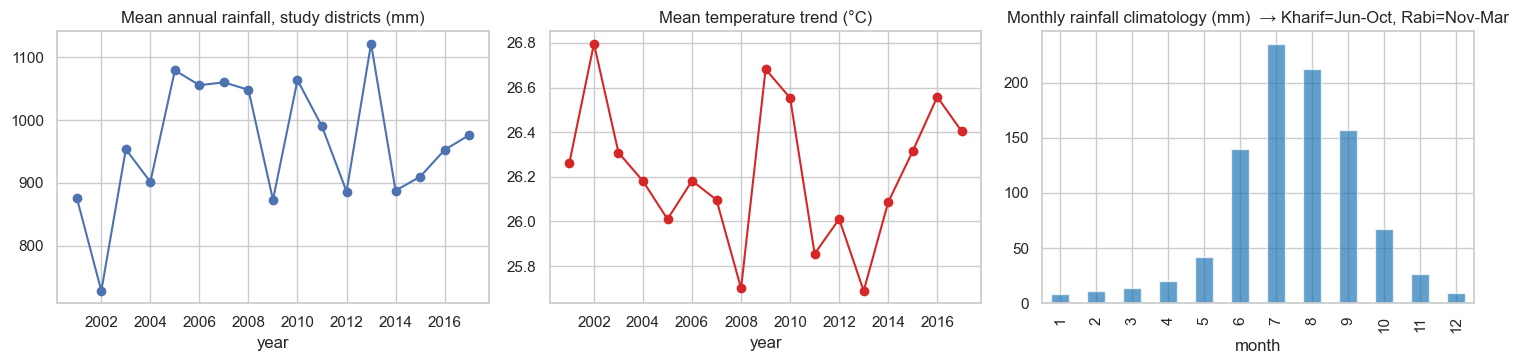

In [5]:
w = weather.copy(); w["year"] = w.date.dt.year; w["month"] = w.date.dt.month
annual = w.groupby(["year"]).agg(rain=("PRECTOTCORR", "sum"), tmean=("T2M", "mean")).reset_index()
annual = annual[annual.year <= 2017]
# average across districts of the annual total rainfall (each district's own total)
rain_y = w[w.year <= 2017].groupby(["state", "district", "year"]).PRECTOTCORR.sum().groupby("year").mean()
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
rain_y.plot(ax=ax[0], marker="o"); ax[0].set_title("Mean annual rainfall, study districts (mm)")
annual.set_index("year").tmean.plot(ax=ax[1], marker="o", color="tab:red"); ax[1].set_title("Mean temperature trend (°C)")
mclim = w.groupby("month").agg(rain=("PRECTOTCORR", "mean"), tmax=("T2M_MAX", "mean"))
(mclim.rain * 30).plot.bar(ax=ax[2], color="tab:blue", alpha=.7); ax[2].set_title("Monthly rainfall climatology (mm)  → Kharif=Jun-Oct, Rabi=Nov-Mar")
plt.tight_layout(); plt.savefig(FIG / "weather_trends.png", dpi=150); plt.show()

## 3. Satellite vegetation: NDVI (MODIS, 16-day composites, ~3 km box around each district centre)

In [6]:
print(inspect.getsource(collect.fetch_ndvi_one))
ndvi = collect.load_ndvi(coords)                       # districts whose NDVI series is downloaded (cached)
have = ndvi[["state", "district"]].drop_duplicates()
coords = coords.merge(have, on=["state", "district"])  # study districts = those with weather AND satellite data
yields = yields.merge(have, on=["state", "district"])
print(ndvi.shape, "->", len(coords), "study districts"); ndvi.head(3)

def fetch_ndvi_one(lat, lon, km=1):
    """NDVI (16-day composite, 250 m) averaged over a ~3x3 km box around the district centre."""
    dates = requests.get(f"{MODIS}/dates", params=dict(latitude=lat, longitude=lon), timeout=60).json()["dates"]
    dates = [d["modis_date"] for d in dates if "A2001001" <= d["modis_date"] <= "A2018100"]
    rows = []
    for i in range(0, len(dates), 10):                    # the API allows 10 composites per call
        chunk = dates[i:i + 10]
        for attempt in range(5):
            try:
                r = requests.get(f"{MODIS}/subset", params=dict(
                    latitude=lat, longitude=lon, band="250m_16_days_NDVI", startDate=chunk[0], endDate=chunk[-1],
                    kmAboveBelow=km, kmLeftRight=km), timeout=180)
                r.raise_for_status()
                for s in r.json()["subset"]:
                    v = np.array(s["data"], dtype=float)
                    v = v[v > -2000]                      # drop fill values
      

,state,district,date,ndvi
0,Andhra Pradesh,Kurnool,2001-01-01,0.336365
1,Andhra Pradesh,Kurnool,2001-01-17,0.319964
2,Andhra Pradesh,Kurnool,2001-02-02,0.301705


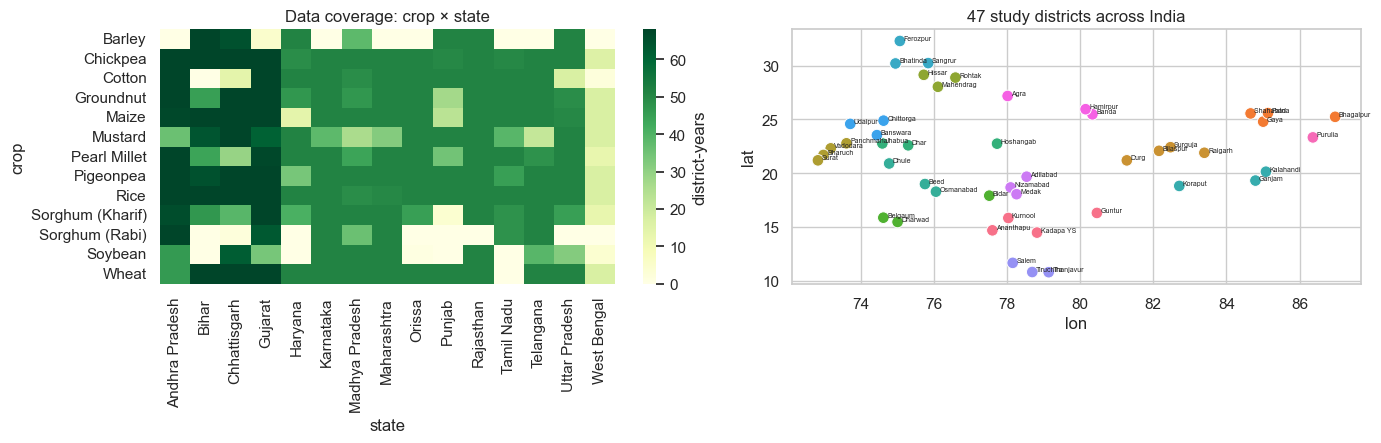

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
cov = yields.pivot_table(index="crop", columns="state", values="yield_kg_ha", aggfunc="count").fillna(0)
sns.heatmap(cov, cmap="YlGn", ax=ax[0], cbar_kws={"label": "district-years"})
ax[0].set_title("Data coverage: crop × state")
sns.scatterplot(data=coords, x="lon", y="lat", hue="state", s=70, ax=ax[1], legend=False)
for _, r in coords.iterrows(): ax[1].text(r.lon + .1, r.lat + .1, r.district.split(" /")[0][:9], fontsize=5)
ax[1].set_title(f"{len(coords)} study districts across India")
plt.tight_layout(); plt.savefig(FIG / "coverage_and_map.png", dpi=150); plt.show()

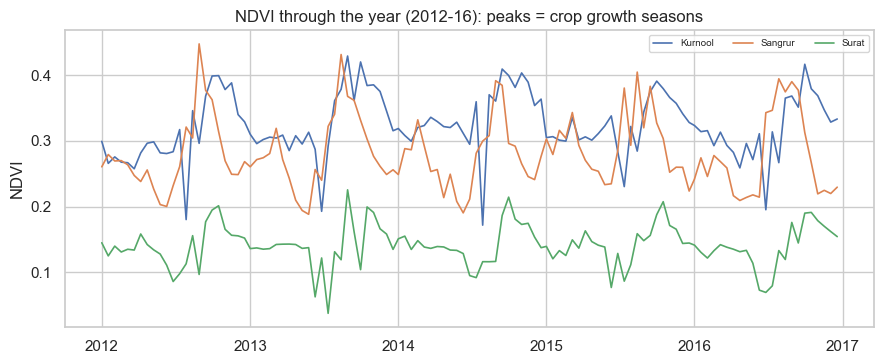

In [8]:
ex = ndvi[ndvi.district.isin(coords.district.iloc[[0, len(coords) // 3, 2 * len(coords) // 3]])].copy()
ex["doy"] = ex.date.dt.dayofyear; ex["label"] = ex.district
fig, ax = plt.subplots(figsize=(9, 3.8))
for (lbl), g in ex[ex.date.dt.year.between(2012, 2016)].groupby("label"):
    g = g.sort_values("date"); ax.plot(g.date, g.ndvi, label=lbl, lw=1.2)
ax.set_title("NDVI through the year (2012-16): peaks = crop growth seasons"); ax.legend(fontsize=7, ncol=3); ax.set_ylabel("NDVI")
plt.tight_layout(); plt.savefig(FIG / "ndvi_curves.png", dpi=150); plt.show()

## 4. Turn daily data into **one row per district × season × year**
Season windows (the crop calendar):
* **Kharif** = 1 June - 31 October of year *Y*
* **Rabi** = 1 November of *Y* - 31 March of *Y+1*  (ICRISAT labels this agricultural year *Y*)

Weather features: total rain, rain in each third of the season (early / mid / late), rainy days, longest dry spell,
mean / max / min temperature, hot days, cold days, humidity, solar radiation.
Satellite features: mean / peak / minimum NDVI, when the peak happens, and early-season greenness.

In [9]:
def tag_season(df):
    m, y = df.date.dt.month, df.date.dt.year
    df = df.copy()
    df["season"] = np.select([m.between(6, 10), m >= 11, m <= 3], ["Kharif", "Rabi", "Rabi"], default=None)
    df["year"] = np.where((df.season == "Rabi") & (m <= 3), y - 1, y)
    start = pd.to_datetime(np.where(df.season == "Kharif", df.year.astype(str) + "-06-01", df.year.astype(str) + "-11-01"))
    df["day"] = (df.date - start).dt.days
    df["third"] = (df.day // 51).clip(upper=2)
    return df.dropna(subset=["season"])

def longest_dry_spell(p):
    run = best = 0
    for v in (p.values < 2.5):
        run = run + 1 if v else 0
        best = max(best, run)
    return best

def weather_features(weather):
    w = tag_season(weather)
    keys = ["state", "district", "season", "year"]
    g = w.groupby(keys)
    f = g.agg(n_days=("day", "size"),
              rain_total=("PRECTOTCORR", "sum"), rain_days=("PRECTOTCORR", lambda s: (s > 2.5).sum()),
              tmean=("T2M", "mean"), tmax=("T2M_MAX", "mean"), tmin=("T2M_MIN", "mean"),
              heat_days=("T2M_MAX", lambda s: (s > 35).sum()), cold_days=("T2M_MIN", lambda s: (s < 8).sum()),
              humidity=("RH2M", "mean"), solar=("ALLSKY_SFC_SW_DWN", "mean"))
    f["dry_spell"] = g.PRECTOTCORR.apply(longest_dry_spell)
    thirds = w.pivot_table(index=keys, columns="third", values="PRECTOTCORR", aggfunc="sum")
    thirds.columns = ["rain_early", "rain_mid", "rain_late"]
    f = f.join(thirds).reset_index()
    return f[f.n_days >= 140].drop(columns="n_days")          # drop incomplete seasons

def satellite_features(ndvi):
    s = tag_season(ndvi)
    keys = ["state", "district", "season", "year"]
    g = s.groupby(keys)
    f = g.agg(ndvi_mean=("ndvi", "mean"), ndvi_max=("ndvi", "max"), ndvi_min=("ndvi", "min"), n=("ndvi", "size"))
    f["ndvi_peak_day"] = s.loc[g.ndvi.idxmax()].set_index(keys).day
    f["ndvi_early"] = s[s.third == 0].groupby(keys).ndvi.mean()
    return f[f.n >= 6].drop(columns="n").reset_index()

wf, sf = weather_features(weather), satellite_features(ndvi)
feat = wf.merge(sf, on=["state", "district", "season", "year"], how="inner")
print("weather rows", len(wf), "| satellite rows", len(sf), "| merged", len(feat))
feat.head()

weather rows 2550 | satellite rows 1645 | merged 1598


,state,district,season,year,rain_total,rain_days,tmean,tmax,tmin,heat_days,...,solar,dry_spell,rain_early,rain_mid,rain_late,ndvi_mean,ndvi_max,ndvi_min,ndvi_peak_day,ndvi_early
0,Andhra Pradesh,Ananthapur,Kharif,2001,528.03,44,26.306013,31.615098,22.162810,13,...,18.372026,22,63.02,111.18,353.83,0.240829,0.359304,0.058196,137,0.145555
1,Andhra Pradesh,Ananthapur,Kharif,2002,326.77,29,27.383595,33.361634,22.569869,49,...,19.812157,34,76.81,45.28,204.68,0.234612,0.267363,0.166396,137,0.221222
2,Andhra Pradesh,Ananthapur,Kharif,2003,308.44,26,27.525817,33.298627,22.913791,31,...,19.172484,33,46.93,78.85,182.66,0.204841,0.289163,0.156135,137,0.192184
3,Andhra Pradesh,Ananthapur,Kharif,2004,297.95,35,26.151438,31.614967,21.846275,0,...,19.824575,32,92.97,94.31,110.67,0.251390,0.299388,0.192386,120,0.232119
4,Andhra Pradesh,Ananthapur,Kharif,2005,678.20,59,25.648235,30.008824,22.164641,2,...,18.320327,23,170.70,275.93,231.57,0.260798,0.306195,0.181333,137,0.216187


## 5. Join yields + features, and define the label

**"Good" must mean good for that crop**, and yields creep upward over the years from better seeds and inputs, so we:
1. **Remove the technology trend** per crop: fit log-yield vs year on the *training* years, then divide each yield by its trend.
2. Split each crop's trend-adjusted yields (training years only) into **terciles**:
   bottom third = **Poor**, middle = **Average**, top third = **Good**.

Because the terciles are computed across *all districts* for a crop, location matters (Punjab wheat is usually Good, central
India wheat usually less so) as well as the season's weather. Thresholds are computed on training years only, so nothing from
the test years leaks in.

In [10]:
data = yields.merge(feat, on=["state", "district", "season", "year"], how="inner")
train_mask = data.year <= TRAIN_END

trend = {}
for crop, g in data[train_mask].groupby("crop"):
    med = g.groupby("year").yield_kg_ha.median()
    slope = np.polyfit(med.index - 2001, np.log(med.values), 1)[0]
    trend[crop] = float(slope)
data["trend_factor"] = np.exp(data.crop.map(trend) * (data.year - 2001))
data["adj_yield"] = data.yield_kg_ha / data.trend_factor

thr = (data[train_mask].groupby("crop").adj_yield.quantile([1 / 3, 2 / 3]).unstack()
       .rename(columns={1 / 3: "poor_below", 2 / 3: "good_above"}))
data = data.join(thr, on="crop")
data["label"] = np.select([data.adj_yield <= data.poor_below, data.adj_yield >= data.good_above], [0, 2], default=1)
data["label_name"] = data.label.map({0: "Poor", 1: "Average", 2: "Good"})
print(data.shape, "rows |", data.crop.nunique(), "crops |", data.district.nunique(), "districts")
print("\nTrend growth per year (%):\n", (pd.Series(trend) * 100).round(2).to_string())
thr.round(0)

(8394, 33) rows | 13 crops | 47 districts

Trend growth per year (%):
 Barley              4.34
Chickpea            2.91
Cotton              5.28
Groundnut           2.42
Maize               4.25
Mustard             4.29
Pearl Millet        2.80
Pigeonpea           3.37
Rice                4.01
Sorghum (Kharif)    2.18
Sorghum (Rabi)      2.85
Soybean             4.26
Wheat               2.30


,poor_below,good_above
crop,,
Barley,925.0,2012.0
Chickpea,614.0,841.0
Cotton,182.0,285.0
Groundnut,762.0,1223.0
Maize,1184.0,1942.0
Mustard,349.0,811.0
Pearl Millet,572.0,949.0
Pigeonpea,454.0,698.0
Rice,977.0,1821.0


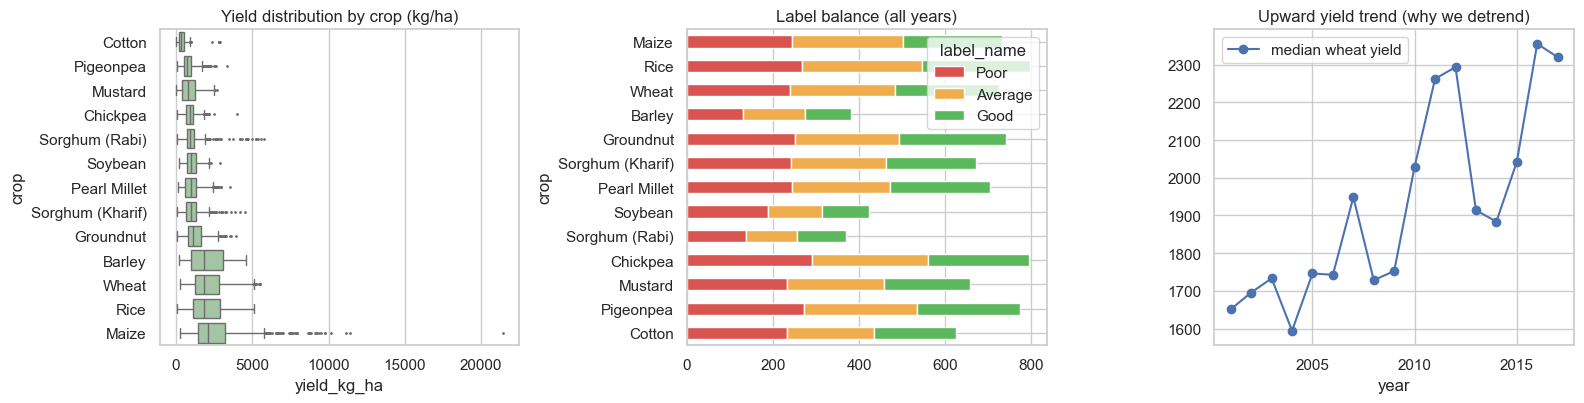

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
order = data.groupby("crop").yield_kg_ha.median().sort_values().index
sns.boxplot(data=data, y="crop", x="yield_kg_ha", order=order, ax=ax[0], color="#9ecb9e", fliersize=1)
ax[0].set_title("Yield distribution by crop (kg/ha)")
lab = data.groupby(["crop", "label_name"]).size().unstack().loc[order, ["Poor", "Average", "Good"]]
lab.plot.barh(stacked=True, ax=ax[1], color=["#d9534f", "#f0ad4e", "#5cb85c"]); ax[1].set_title("Label balance (all years)")
ex = data[data.crop == "Wheat"].groupby("year").yield_kg_ha.median()
ex.plot(ax=ax[2], marker="o", label="median wheat yield"); ax[2].set_title("Upward yield trend (why we detrend)"); ax[2].legend()
plt.tight_layout(); plt.savefig(FIG / "yield_distribution_labels.png", dpi=150); plt.show()

## 6. Which conditions go with good yields? (quick EDA)
Correlation of each seasonal feature with the **trend-adjusted yield**, separately for Kharif and Rabi.

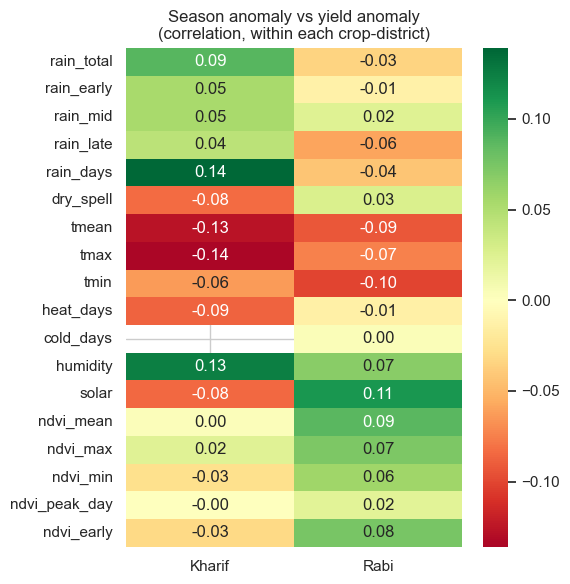

In [12]:
fcols = ["rain_total", "rain_early", "rain_mid", "rain_late", "rain_days", "dry_spell", "tmean", "tmax", "tmin", "heat_days",
         "cold_days", "humidity", "solar", "ndvi_mean", "ndvi_max", "ndvi_min", "ndvi_peak_day", "ndvi_early"]
# within each crop-district, compare against that district's own average -> isolates the weather effect
d2 = data.copy()
for c in fcols + ["adj_yield"]:
    d2[c] = d2[c] - d2.groupby(["crop", "district"])[c].transform("mean")
corr = pd.DataFrame({s: d2[d2.season == s][fcols].corrwith(d2[d2.season == s].adj_yield) for s in ["Kharif", "Rabi"]})
fig, ax = plt.subplots(figsize=(5.8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlGn", center=0, ax=ax)
ax.set_title("Season anomaly vs yield anomaly\n(correlation, within each crop-district)")
plt.tight_layout(); plt.savefig(FIG / "feature_correlation.png", dpi=150); plt.show()

The signals are **modest** (|r| ≤ 0.14) but point the way agronomy expects: cooler, wetter and more humid Kharif seasons, and
sunnier, greener (higher NDVI) Rabi seasons, go with better yields. Within one district, weather explains only a small share of
year-to-year differences, which is why the district's own history turns out to matter most in notebook 02.

## 7. "Normal" conditions per district-season
At prediction time a farmer asks about the *coming* season, whose weather is not known yet. So we also store each district's
**normal** (average over the training years) conditions. These (a) tell the model the district's climate and
(b) are the starting point for a "what if it's a dry / normal / wet season" scenario.

In [13]:
normals = (feat[feat.year <= TRAIN_END].groupby(["state", "district", "season"])[fcols].mean().reset_index())
print(normals.shape); normals.head()

(94, 21)


,state,district,season,rain_total,rain_early,rain_mid,rain_late,rain_days,dry_spell,tmean,...,tmin,heat_days,cold_days,humidity,solar,ndvi_mean,ndvi_max,ndvi_min,ndvi_peak_day,ndvi_early
0,Andhra Pradesh,Ananthapur,Kharif,449.280000,112.415385,165.400000,171.464615,39.692308,26.923077,26.327149,...,22.087350,12.692308,0.0,72.075480,19.073328,0.254596,0.319600,0.171986,123.230769,0.219033
1,Andhra Pradesh,Ananthapur,Rabi,64.203846,41.301538,5.427692,17.474615,6.461538,102.538462,24.876084,...,18.200372,40.384615,0.0,56.613616,20.336035,0.254421,0.311280,0.224893,9.615385,0.282808
2,Andhra Pradesh,Guntur,Kharif,843.225385,202.249231,308.893846,332.082308,66.000000,15.615385,28.323369,...,24.946737,27.307692,0.0,76.617506,17.253494,0.333280,0.402692,0.239696,122.000000,0.286259
3,Andhra Pradesh,Guntur,Rabi,131.781538,94.460000,13.656923,23.664615,9.153846,83.000000,25.401501,...,19.712795,41.615385,0.0,69.833925,18.113699,0.322954,0.379701,0.276486,5.923077,0.353459
4,Andhra Pradesh,Kadapa YSR,Kharif,530.002308,119.275385,172.250000,238.476923,50.615385,20.538462,27.921212,...,23.637034,39.692308,0.0,69.138492,18.606606,0.322286,0.397485,0.224037,117.076923,0.271757


In [14]:
data.to_csv(PROC / "model_table.csv", index=False)
normals.to_csv(PROC / "normals.csv", index=False)
feat.to_csv(PROC / "season_features.csv", index=False)
coords.to_csv(PROC / "coords.csv", index=False)
json.dump(dict(trend=trend, thresholds=thr.to_dict(orient="index"), train_end=TRAIN_END, fcols=fcols),
          open(PROC / "label_meta.json", "w"), indent=1)
print("saved:", [p.name for p in PROC.iterdir()])
print(f"\nmodel table: {len(data):,} rows | train {int(train_mask.sum()):,} | test {int((~train_mask).sum()):,}")

saved: ['coords.csv', 'integration_stats.json', 'label_meta.json', 'leaf_test_predictions.csv', 'model_results.csv', 'model_summary.json', 'model_table.csv', 'normals.csv', 'season_features.csv']

model table: 8,394 rows | train 6,451 | test 1,943
